In [1]:
import numpy as np
import matplotlib.pyplot as plt
import math

In [3]:
x_train = [1.0, 2.0]
y_train = [300.0, 500.0]

m = len(x_train)

print(f"x_train = {x_train}")
print(f"y_train = {y_train}")
print(f"No of samples = {m}")

x_train = [1.0, 2.0]
y_train = [300.0, 500.0]
No of samples = 2


In [9]:
# Function to Compute Model 

def compute_model_output (x, w, b):
  m = len(x)
  f_wb = np.zeros(m)

  for i in range(m):
    f_wb[i] = w * x[i] + b

  return f_wb

In [10]:
# Function to Calculate Cost

def compute_cost (x,y,w,b):
  m = len(x)
  cost = 0
  total_cost = 0

  for i in range(m):
    f_wb = w*x[i] + b
    cost = cost + (f_wb - y[i])**2

  total_cost = cost * (1/(2*m))

  return total_cost

In [21]:
# Gradient Descent for Optimizing the cost function

def compute_gradient(x,y,w,b):
  m = len(x)
  dj_dw = 0
  dj_db = 0

  dj_dw_i=0
  dj_db_i=0

  for i in range(m):
    f_wb = w*x[i] + b
    dj_dw_i = (f_wb - y[i])*x[i]
    dj_db_i = f_wb - y[i]
    dj_dw += dj_dw_i
    dj_db += dj_db_i

  dj_dw = dj_dw/m
  dj_db = dj_db/m

  return dj_dw, dj_db

def gradient_descent(x,y,w_in,b_in,alpha,num_iters,cost_function,gradient_function):
    w = w_in
    b = b_in
    J_hist = []

    for i in range(num_iters):
      dj_dw, dj_db = compute_gradient(x,y,w,b)

      w = w - alpha*dj_dw
      b = b - alpha*dj_db

      J_hist.append(cost_function(x,y,w,b))

      # Print the values while iterating.
      if i%math.ceil(num_iters/10) == 0:
        print(f"Iteration {i} : Cost {J_hist[-1]:0.3e}", f"dj_dw: {dj_dw:0.3e}, dj_db:{dj_db:0.3e}",
              f"w:{w}, b:{b}")

    return w,b,J_hist

In [27]:
# Initialize parameters
w_init = 0
b_init = 0

iterations = 20000
tmp_alpha = 1.0e-2

w_final, b_final, J_hist = gradient_descent(x_train, y_train, w_init, b_init, tmp_alpha,iterations,compute_cost, compute_gradient)

print(f"(w,b) found by gradient descent: ({w_final:8.4f},{b_final:8.4f})")

Iteration 0 : Cost 7.927e+04 dj_dw: -6.500e+02, dj_db:-4.000e+02 w:6.5, b:4.0
Iteration 2000 : Cost 7.929e-01 dj_dw: -1.789e-01, dj_db:2.895e-01 w:197.5488109193384, b:103.96610724536305
Iteration 4000 : Cost 4.281e-02 dj_dw: -4.158e-02, dj_db:6.727e-02 w:199.43046754349498, b:100.92152287232139
Iteration 6000 : Cost 2.311e-03 dj_dw: -9.660e-03, dj_db:1.563e-02 w:199.86766944191632, b:100.21411534072959
Iteration 8000 : Cost 1.248e-04 dj_dw: -2.245e-03, dj_db:3.632e-03 w:199.9692530664359, b:100.04974958355662
Iteration 10000 : Cost 6.735e-06 dj_dw: -5.215e-04, dj_db:8.439e-04 w:199.9928559666243, b:100.01155928881862
Iteration 12000 : Cost 3.636e-07 dj_dw: -1.212e-04, dj_db:1.961e-04 w:199.99834008771117, b:100.00268579450183
Iteration 14000 : Cost 1.963e-08 dj_dw: -2.816e-05, dj_db:4.556e-05 w:199.9996143202779, b:100.00062404289908
Iteration 16000 : Cost 1.060e-09 dj_dw: -6.542e-06, dj_db:1.059e-05 w:199.99991038752526, b:100.00014499602986
Iteration 18000 : Cost 5.721e-11 dj_dw: -1

Multiple Linear Regression

In [34]:
X_train = np.array([[2104, 5, 1, 45], [1416, 3, 2, 40], [852, 2, 1, 35]])
y_train = np.array([460, 232, 178])

print(f"X Shape: {X_train.shape}")
print(f"y Shape: {y_train.shape}")

X Shape: (3, 4)
y Shape: (3,)


In [53]:
# Compute Prediction from model
def model_compute(X,w,b):
  f = np.dot(w,X) + b
  return f

# Compute Cost
def cost_compute(X,y,w,b):
  m = X.shape[0]
  cost = 0.0

  for i in range(m):
    f_wb_i = np.dot(X[i],w) + b
    cost += (f_wb_i - y[i])**2

  cost = cost/(2*m)
  return cost

# Gradient Descent
def gradient_compute(X,y,w,b):
  m,n = X.shape
  dj_dw = np.zeros(n)
  dj_db = 0.0

  for i in range(m):
    f_wb_i = np.dot(X[i],w) + b
    err_i = (f_wb_i - y[i])
    for j in range(n):
      dj_dw[j] += err_i * X[i,j]

    dj_db += err_i

  dj_dw = dj_dw/m
  dj_db = dj_db/m

  return dj_dw,dj_db

def gradient_descent(X,y,w_in,b_in,alpha,num_iters,cost_function,gradient_function):
  w = w_in
  b = b_in

  J_hist = []


  for i in range(num_iters):
    dj_dw, dj_db = gradient_function(X,y,w,b)

    w = w - alpha*dj_dw
    b = b - alpha*dj_db

    J_hist.append(cost_function(X,y,w,b))

    if i%math.ceil(num_iters/20) == 0:
      print( f"Iteration {i} : Cost {J_hist[-1] : 6.3e}" )


  return w,b, J_hist

In [69]:
#Initialize parameters

n = X_train.shape[1]
w_init = np.zeros((n,))
b_init = 0.0
iterations = 20000
alpha = 1.8e-11

w_final, b_final, J_hist = gradient_descent(X_train, y_train, w_init, b_init, alpha, iterations, cost_compute, gradient_compute)

print(f"b,w found by gradient descent: {b_final : 6.3e},{w_final}")

Iteration 0 : Cost  4.951e+04
Iteration 1000 : Cost  4.549e+04
Iteration 2000 : Cost  4.180e+04
Iteration 3000 : Cost  3.842e+04
Iteration 4000 : Cost  3.531e+04
Iteration 5000 : Cost  3.246e+04
Iteration 6000 : Cost  2.984e+04
Iteration 7000 : Cost  2.744e+04
Iteration 8000 : Cost  2.524e+04
Iteration 9000 : Cost  2.322e+04
Iteration 10000 : Cost  2.136e+04
Iteration 11000 : Cost  1.966e+04
Iteration 12000 : Cost  1.810e+04
Iteration 13000 : Cost  1.667e+04
Iteration 14000 : Cost  1.535e+04
Iteration 15000 : Cost  1.414e+04
Iteration 16000 : Cost  1.304e+04
Iteration 17000 : Cost  1.202e+04
Iteration 18000 : Cost  1.109e+04
Iteration 19000 : Cost  1.023e+04
b,w found by gradient descent:  6.947e-05,[1.16576332e-01 2.70642903e-04 8.59960395e-05 2.89799032e-03]


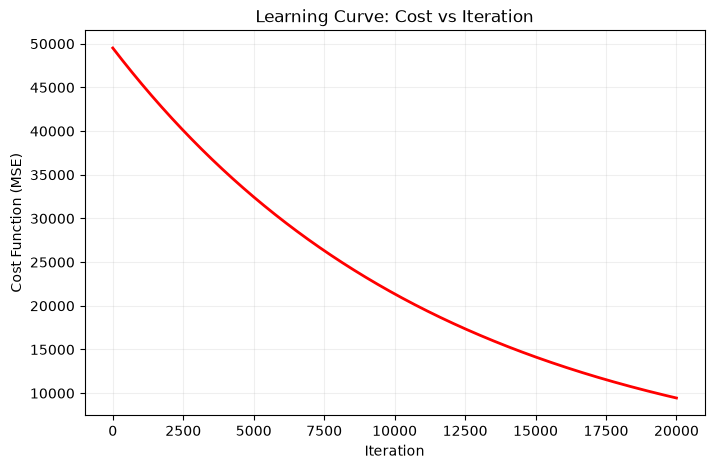

In [73]:
# Plotting Loss curve
plt.figure(figsize=(8,5))
plt.plot(J_hist, color='red',linewidth=2)
plt.xlabel("Iteration")
plt.ylabel("Cost Function (MSE)")
plt.title("Learning Curve: Cost vs Iteration")
plt.grid(True,alpha=0.2)
plt.show()